# TP2 - Ejercicio 1: Reconocimiento de voz con CRNN

Clasifico:

* yes
* no
* stop
* go 

de Speech Commands v2. 

Usando el subconjunto de cuatro clases permitido por la consigna para reducir costo en CPU, manteniendo contrastes entre comienzos y finales
fonéticos. 

Los resultados no se generalizan automáticamente a diez clases ni a hablantes fuera del corpus.

## 1. Datos y particiones por hablante

Leemos el archivo oficial, usamos sus listas de validación y prueba y comprobamos que los identificadores de hablante no se crucen.

In [1]:
import io
import json
import math
import os
import random
import tarfile
import time
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import wavfile
from scipy.signal import resample_poly
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# configuración y constantes del experimento
ROOT = Path.cwd()
CLASSES = ("yes", "no", "stop", "go")
SR, N_FFT, HOP, N_MELS = 16000, 1024, 512, 64
PROFILE = os.getenv("TP2_PROFILE", "full")
SMOKE = PROFILE == "smoke"
OUT = ROOT / "resultados" / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

def load_wav(stream):
    sr, raw = wavfile.read(stream)
    if raw.dtype.kind in "iu":
        info = np.iinfo(raw.dtype)
        signal = raw.astype(np.float32)
        if raw.dtype.kind == "u":
            signal -= (info.max + 1) / 2
        signal /= max(abs(info.min), (info.max + 1) / 2 if raw.dtype.kind == "u" else info.max + 1)
    else:
        signal = raw.astype(np.float32)
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if sr != SR:
        gcd = math.gcd(sr, SR)
        signal = resample_poly(signal, SR // gcd, sr // gcd).astype(np.float32)
    return np.pad(signal[:SR], (0, max(0, SR - len(signal))))

def mel_filter():
    def mel(hz):
        return 2595 * np.log10(1 + hz / 700)
    hz = 700 * (10 ** (np.linspace(mel(0), mel(SR / 2), N_MELS + 2) / 2595) - 1)
    f = np.fft.rfftfreq(N_FFT, 1 / SR)
    filters = np.maximum(0, np.minimum((f - hz[:-2, None]) / (hz[1:-1, None] - hz[:-2, None]),
                                       (hz[2:, None] - f) / (hz[2:, None] - hz[1:-1, None])))
    return torch.tensor(filters, dtype=torch.float32), hz[1:-1]

def to_mel(audio):
    bank, _ = mel_filter()
    stft = torch.stft(torch.as_tensor(np.stack(audio)), N_FFT, hop_length=HOP,
                      window=torch.hann_window(N_FFT), return_complex=True, pad_mode="constant")
    energy = (bank @ stft.abs().square()).clamp_min(1e-10)
    db = 10 * energy.log10()
    return (db - db.amax(dim=(-2, -1), keepdim=True)).clamp_min(-80).numpy()

def smoke_subset(x, y, split, names):
    rng = np.random.default_rng(42)
    indices = np.concatenate([rng.choice(np.flatnonzero((split == key) & (y == c)), size=n, replace=False)
                              for key, n in (("train", 20), ("val", 8), ("test", 8)) for c in range(len(CLASSES))])
    return x[indices], y[indices], split[indices], names[indices]

def load_data():
    source = Path(os.getenv("SPEECH_COMMANDS", str(ROOT / "data" / "speech.tar.gz")))
    if not source.exists():
        raise FileNotFoundError(f"Falta Speech Commands v2: {source}. Ver README.")
    stat = source.stat()
    signature = json.dumps([str(source.resolve()), stat.st_size, stat.st_mtime_ns, CLASSES, SR, N_FFT, HOP, N_MELS])
    cache = OUT / "mel_cache.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as data:
            if json.loads(str(data["signature"]))[1:] == json.loads(signature)[1:]:
                return data["x"], data["y"], data["split"], data["names"]
    full_cache = ROOT / "resultados" / "full" / "mel_cache.npz"
    if SMOKE and full_cache.exists():
        with np.load(full_cache, allow_pickle=False) as data:
            if json.loads(str(data["signature"]))[1:] == json.loads(signature)[1:]:
                x, y, split, names = smoke_subset(data["x"], data["y"], data["split"], data["names"])
                np.savez(cache, x=x, y=y, split=split, names=names, signature=signature)
                return x, y, split, names
    x, y, names, waveforms = [], [], [], []
    lists = {}
    with tarfile.open(source, "r|gz") as archive:
        for member in archive:
            name = member.name.removeprefix("./")
            parent, _, file = name.rpartition("/")
            if not member.isfile():
                continue
            if name in ("validation_list.txt", "testing_list.txt"):
                with archive.extractfile(member) as stream:
                    lists[name] = set(stream.read().decode().splitlines())
            elif parent in CLASSES and file.endswith(".wav"):
                with archive.extractfile(member) as stream:
                    waveforms.append(load_wav(io.BytesIO(stream.read())))
                y.append(CLASSES.index(parent))
                names.append(name)
                if len(waveforms) == 128:
                    x.append(to_mel(waveforms))
                    waveforms.clear()
        if waveforms:
            x.append(to_mel(waveforms))
    if len(lists) != 2 or not x:
        raise ValueError("Archivo sin audios seleccionados o sin listas oficiales.")
    split = np.array(["val" if name in lists["validation_list.txt"] else
                      "test" if name in lists["testing_list.txt"] else "train" for name in names])
    y, x, names = np.asarray(y), np.concatenate(x), np.asarray(names)
    speakers = [{str(name).split("/")[-1].split("_nohash_")[0] for name in names[split == key]}
                for key in ("train", "val", "test")]
    assert all(speakers) and not any(speakers[i] & speakers[j] for i, j in ((0, 1), (0, 2), (1, 2)))
    if SMOKE:
        x, y, split, names = smoke_subset(x, y, split, names)
    np.savez(cache, x=x, y=y, split=split, names=names, signature=signature)
    return x, y, split, names

def loaders(x, y, split):
    train = x[split == "train"]
    mean, std = float(train.mean(dtype=np.float64)), max(1e-6, float(train.std(dtype=np.float64)))
    xx = (x - mean) / std
    sets = {key: TensorDataset(torch.from_numpy(xx[split == key]), torch.from_numpy(y[split == key]).long())
            for key in ("train", "val", "test")}
    return sets, mean, std

# carga y verificación de particiones
mel, etiquetas, particiones, archivos = load_data()
datos, media, desvio = loaders(mel, etiquetas, particiones)
print("Dispositivo:", DEVICE, "| espectrogramas:", mel.shape)
print(f"Normalización global (train): media={media:.3f}, desvío={desvio:.3f}")
display(pd.crosstab(particiones, [CLASSES[i] for i in etiquetas]))


Dispositivo: cpu | espectrogramas: (15737, 64, 32)
Normalización global (train): media=-55.058, desvío=19.734


col_0,go,no,stop,yes
row_0,,,,
test,402,405,411,419
train,3106,3130,3111,3228
val,372,406,350,397


## 2. Ocho ejemplos de espectrogramas

Convertimos la señal acústica en una representación bidimensional tiempo-frecuencia que la CNN analiza mediante convoluciones espaciales. Para eso contrastamos cuatro grabaciones de yes y cuatro grabaciones de clases distintas. Usamos dB relativos al máximo del audio y un umbral descriptivo de −25 dB para ubicar su tramo activo.

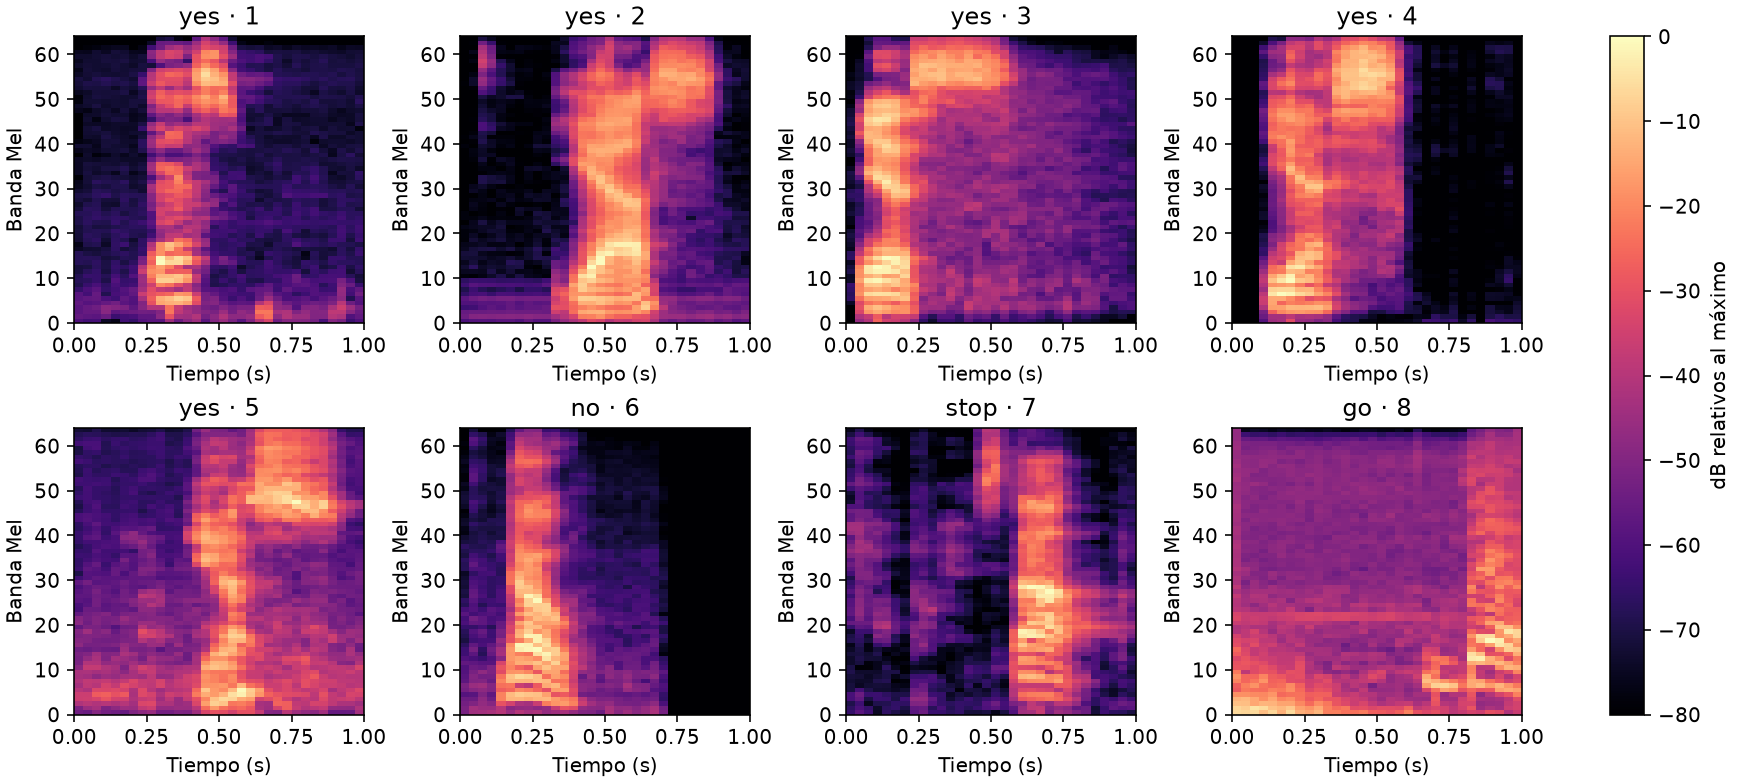

,clase,archivo,inicio,fin,duracion,baja_hz,alta_hz,pico_s,pico_hz
0,yes,yes/65040d9b_nohash_1.wav,0.256,0.672,0.416,183.327,5437.394,0.288,504.535
1,yes,yes/879a2b38_nohash_4.wav,0.384,0.864,0.480,254.544,2731.036,0.480,504.535
2,yes,yes/c4e00ee9_nohash_1.wav,0.032,0.544,0.512,292.278,5204.006,0.096,458.730
3,yes,yes/954f190f_nohash_1.wav,0.128,0.544,0.416,218.245,5680.008,0.160,218.245
4,yes,yes/cdee383b_nohash_2.wav,0.416,0.896,0.480,149.737,4163.630,0.768,3800.762
5,no,no/d78858d9_nohash_0.wav,0.128,0.384,0.256,292.278,1293.902,0.256,552.151
6,stop,stop/23da904f_nohash_1.wav,0.480,0.832,0.352,706.593,1454.658,0.704,1372.722
7,go,go/51f4d5b0_nohash_0.wav,0.000,0.992,0.992,27.671,762.197,0.896,653.104


In [2]:
def plot_mels(mels, y, split, names, show=False):
    train = np.flatnonzero(split == "train")
    rng = np.random.default_rng(42)
    # Ocho audios distintos: cuatro yes y uno por clase.
    first = rng.choice(train[y[train] == 0], 4, replace=False)
    second = [rng.choice(np.setdiff1d(train[y[train] == c], first)) for c in range(len(CLASSES))]
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), layout="constrained")
    _, centers = mel_filter()
    stats = []
    for i, ax in zip(np.r_[first, second], axes.flat):
        mel_img = mels[i]
        img = ax.imshow(mel_img, origin="lower", aspect="auto", extent=(0, 1, 0, 64), cmap="magma", vmin=-80, vmax=0)
        ax.set(title=f"{CLASSES[y[i]]} · {len(stats)+1}", xlabel="Tiempo (s)", ylabel="Banda Mel")
        active = np.flatnonzero(mel_img.max(axis=0) >= -25)
        weights = (10 ** (mel_img[:, active] / 10)).sum(axis=1)
        cdf = np.cumsum(weights) / weights.sum()
        lo, hi = centers[np.searchsorted(cdf, [.1, .9])]
        peak = np.unravel_index(mel_img.argmax(), mel_img.shape)
        stats.append(dict(clase=CLASSES[y[i]], archivo=str(names[i]), inicio=float(active[0] * HOP / SR),
                          fin=float(active[-1] * HOP / SR), duracion=float((active[-1] - active[0]) * HOP / SR),
                          baja_hz=float(lo), alta_hz=float(hi),
                          pico_s=float(peak[1] * HOP / SR), pico_hz=float(centers[peak[0]])))
    fig.colorbar(img, ax=list(axes.flat), label="dB relativos al máximo")
    fig.savefig(OUT / "audio_mels.png", dpi=145)
    if show:
        plt.show()
    plt.close(fig)
    return stats

resumen = plot_mels(mel, etiquetas, particiones, archivos)
display(Image(filename=str(OUT / "audio_mels.png")))
display(pd.DataFrame(resumen).round(3))


Lee inicio, fin y duración como una estimación a partir de las tramas activas, en lugar de leerlo como una transcripción fonética. Fuera de ese tramo puede haber ruido de baja energía. Los límites de frecuencia delimitan el 80 % central de la energía, y el pico ubica la celda más intensa. Bandas brillantes persistentes señalan energía repetida en una región espectral, y no identifican por sí solas un fonema.